# Focused U.S. accuracy experiments

This copy starts from the HGB tuning notebook. We keep its official training cohort and conservative features. We do not rerun the randomized search.

We compare the original tuned HGB with two nearby settings: stronger leaf/L2 regularization, and a slower learning rate with more iterations. Thresholds are limited to .45, .50 and .55. No new feature family is admitted because launch provenance remains uncertain.

Three outer folds estimate the procedure. Two inner folds choose settings and threshold by accuracy, allowing at most .002 AUC loss and .01 failure-recall loss relative to the original HGB. Changes need at least .003 inner accuracy gain. All preprocessing stays inside each fit. These rules were fixed before executing this notebook.

In [1]:
from pathlib import Path
import sys, time, warnings
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'utils' / 'preprocessing.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from utils.us_modeling import load_us_training_data, CONSERVATIVE_POLICY
from utils.us_validation import INPUTS
from utils.us_accuracy import focused_experiment
X, y, project_ids = load_us_training_data(ROOT)
X = X[INPUTS].copy()
assert len(X) == 26945 and project_ids.is_unique
print('Training campaigns:', len(X), 'success rate:', y.mean())
print('Feature policy:', CONSERVATIVE_POLICY)

Training campaigns: 26945 success rate: 0.546149563926517
Feature policy: {'include_timing': False, 'include_flags': False, 'include_reward': False, 'exclude_renamed': True}


In [2]:
decision, folds, inner_trials, final_inner, old_p, new_p, thresholds = focused_experiment(X, y)
display(pd.DataFrame({'Original tuned HGB': decision['original_metrics'],
                      'Focused procedure': decision['focused_metrics']}).T.round(4))
display(folds.round(4))
display(inner_trials[['fold', 'candidate', 'threshold', 'accuracy', 'roc_auc',
                      'failure_recall', 'success_f1']].round(4))

Focused experiment: outer fold 1/3 complete


Focused experiment: outer fold 2/3 complete


Focused experiment: outer fold 3/3 complete


,accuracy,roc_auc,brier,tn,fp,fn,tp,failure_precision,failure_recall,failure_f1,failure_support,success_precision,success_recall,success_f1,success_support
Original tuned HGB,0.6693,0.7239,0.2096,6814.0,5415.0,3495.0,11221.0,0.661,0.5572,0.6047,12229.0,0.6745,0.7625,0.7158,14716.0
Focused procedure,0.6693,0.7239,0.2096,6814.0,5415.0,3495.0,11221.0,0.661,0.5572,0.6047,12229.0,0.6745,0.7625,0.7158,14716.0


,fold,procedure,candidate,threshold,accuracy,roc_auc,brier,tn,fp,fn,tp,failure_precision,failure_recall,failure_f1,failure_support,success_precision,success_recall,success_f1,success_support
0,1,original,original,0.5,0.6697,0.7245,0.2097,2246,1831,1136,3769,0.6641,0.5509,0.6022,4077.0,0.6730,0.7684,0.7176,4905.0
1,1,focused,original,0.5,0.6697,0.7245,0.2097,2246,1831,1136,3769,0.6641,0.5509,0.6022,4077.0,0.6730,0.7684,0.7176,4905.0
2,2,original,original,0.5,0.6688,0.7236,0.2095,2286,1790,1185,3721,0.6586,0.5608,0.6058,4076.0,0.6752,0.7585,0.7144,4906.0
3,2,focused,original,0.5,0.6688,0.7236,0.2095,2286,1790,1185,3721,0.6586,0.5608,0.6058,4076.0,0.6752,0.7585,0.7144,4906.0
4,3,original,original,0.5,0.6695,0.7238,0.2096,2282,1794,1174,3731,0.6603,0.5599,0.6059,4076.0,0.6753,0.7607,0.7154,4905.0
5,3,focused,original,0.5,0.6695,0.7238,0.2096,2282,1794,1174,3731,0.6603,0.5599,0.6059,4076.0,0.6753,0.7607,0.7154,4905.0


,fold,candidate,threshold,accuracy,roc_auc,failure_recall,success_f1
0,1,original,0.45,0.6646,0.7150,0.4807,0.7269
1,1,original,0.50,0.6656,0.7150,0.5573,0.7117
2,1,original,0.55,0.6605,0.7150,0.6322,0.6876
3,1,regularized,0.45,0.6635,0.7165,0.4804,0.7258
4,1,regularized,0.50,0.6671,0.7165,0.5616,0.7124
5,1,regularized,0.55,0.6635,0.7165,0.6373,0.6899
6,1,slower,0.45,0.6639,0.7164,0.4740,0.7275
7,1,slower,0.50,0.6667,0.7164,0.5563,0.7131
8,1,slower,0.55,0.6619,0.7164,0.6338,0.6888
0,2,original,0.45,0.6602,0.7149,0.4689,0.7248


We promote a change only if pooled outer accuracy increases by at least .003, AUC loses no more than .002, failure recall loses no more than .01, and accuracy improves in at least two of three folds. This is a practical guardrail, not a significance test. The outer comparison also informs promotion, so the final reported score remains development evidence. Prior tuning means these folds are not fully independent of candidate design.

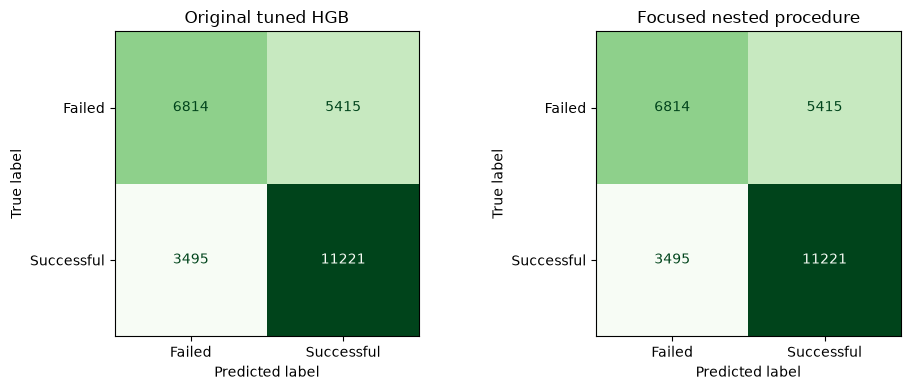

procedure,focused,original,accuracy_change
fold,,,
1,0.6697,0.6697,0.0
2,0.6688,0.6688,0.0
3,0.6695,0.6695,0.0


Accept improvement: False
Final setting: original threshold: 0.5
Restricted nested development comparison after prior tuning; promotion uses outer results and adds selection optimism. No significance claim from three overlapping folds.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label, probability, threshold in [
    (axes[0], 'Original tuned HGB', old_p, 0.5),
    (axes[1], 'Focused nested procedure', new_p, thresholds)]:
    ConfusionMatrixDisplay.from_predictions(y, probability >= threshold, labels=[0, 1],
        display_labels=['Failed', 'Successful'], cmap='Greens', colorbar=False, ax=ax)
    ax.set_title(label)
plt.tight_layout(); plt.show()
paired = folds.pivot(index='fold', columns='procedure', values='accuracy')
paired['accuracy_change'] = paired.focused - paired.original
display(paired.round(4))
print('Accept improvement:', decision['accept_improvement'])
print('Final setting:', decision['final_candidate'], 'threshold:', decision['final_threshold'])
print(decision['limitation'])

The other model families are compared in `06_us_validation.ipynb` using a separate restricted nested comparison. We retain their existing tuning results as development history. A small accuracy difference alone does not establish a better campaign-risk model.

The decision below is a local handoff to the validation notebook. It contains no reserved data. Run the validation notebook next to refit and verify the final artifact. Reserved evaluation needs a separate approved protocol.

In [4]:
folder = ROOT / 'models'
folder.mkdir(exist_ok=True)
(folder / 'us_accuracy_decision.json').write_text(json.dumps(decision, indent=2, allow_nan=False) + '\n')
folds.to_csv(folder / 'us_accuracy_outer_folds.csv', index=False)
display(final_inner.round(4))
print('Saved local accuracy decision. Run 06_us_validation.ipynb next.')

,candidate,threshold,accuracy,roc_auc,brier,tn,fp,fn,tp,failure_precision,failure_recall,failure_f1,failure_support,success_precision,success_recall,success_f1,success_support
0,original,0.45,0.6670,0.7213,0.2105,5880,6349,2625,12091,0.6914,0.4808,0.5672,12229.0,0.6557,0.8216,0.7293,14716.0
1,original,0.50,0.6681,0.7213,0.2105,6896,5333,3610,11106,0.6564,0.5639,0.6066,12229.0,0.6756,0.7547,0.7130,14716.0
2,original,0.55,0.6642,0.7213,0.2105,7849,4380,4669,10047,0.6270,0.6418,0.6343,12229.0,0.6964,0.6827,0.6895,14716.0
3,regularized,0.45,0.6668,0.7209,0.2106,5896,6333,2644,12072,0.6904,0.4821,0.5678,12229.0,0.6559,0.8203,0.7290,14716.0
4,regularized,0.50,0.6692,0.7209,0.2106,6924,5305,3609,11107,0.6574,0.5662,0.6084,12229.0,0.6768,0.7548,0.7136,14716.0
5,regularized,0.55,0.6643,0.7209,0.2106,7855,4374,4672,10044,0.6270,0.6423,0.6346,12229.0,0.6966,0.6825,0.6895,14716.0
6,slower,0.45,0.6661,0.7210,0.2106,5871,6358,2640,12076,0.6898,0.4801,0.5662,12229.0,0.6551,0.8206,0.7286,14716.0
7,slower,0.50,0.6687,0.7210,0.2106,6895,5334,3594,11122,0.6574,0.5638,0.6070,12229.0,0.6759,0.7558,0.7136,14716.0
8,slower,0.55,0.6634,0.7210,0.2106,7828,4401,4669,10047,0.6264,0.6401,0.6332,12229.0,0.6954,0.6827,0.6890,14716.0


Saved local accuracy decision. Run 06_us_validation.ipynb next.
